
Fichier chargé : lte.csv | Dimensions : 2021 lignes x 23 colonnes

--- APERÇU DES COLONNES ET VALEURS MANQUANTES ---
  technology  rsrp  rsrq  rssi  pci ta  is_connected  rel_time  altitude
0     4G_LTE   -65    -6   -51    2  0             1  1.016413     0.715
1     4G_LTE   -65    -6   -51    2  0             1  2.020826     0.715
2     4G_LTE   -65    -6   -51    2  0             1  3.032316     0.719
3     4G_LTE   -65    -6   -51    2  0             1  4.051300     0.718
4     4G_LTE   -65    -6   -51    2  0             1  5.049825     0.697

Valeurs non numériques ou manquantes détectées :
 - rsrp       : 0 valeurs invalides / 'Unavailable'
 - rsrq       : 0 valeurs invalides / 'Unavailable'
 - rssi       : 0 valeurs invalides / 'Unavailable'
 - ta         : 547 valeurs invalides / 'Unavailable'
 - altitude   : 0 valeurs invalides / 'Unavailable'

--- RÉSUMÉ APRÈS NETTOYAGE ---
Durée totale        : 1219 secondes
Altitude min / max  : 0.00 m -> 49.62 m
RSRP min / max      : -1

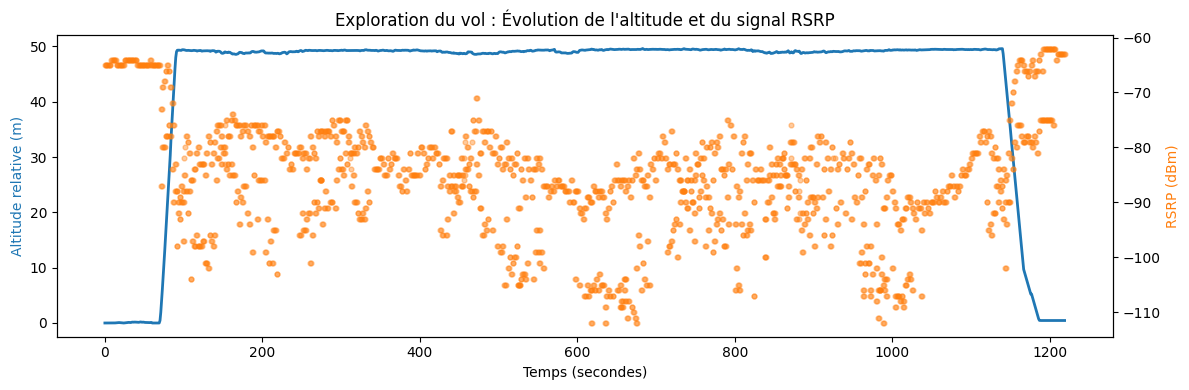

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



--- RÉSULTATS SUR LE JEU DE TEST (366 secondes) ---
RMSE LightGBM brut         : 6.06 m
RMSE après Filtre Kalman   : 6.06 m
Erreur moyenne (MAE)       : 2.49 m


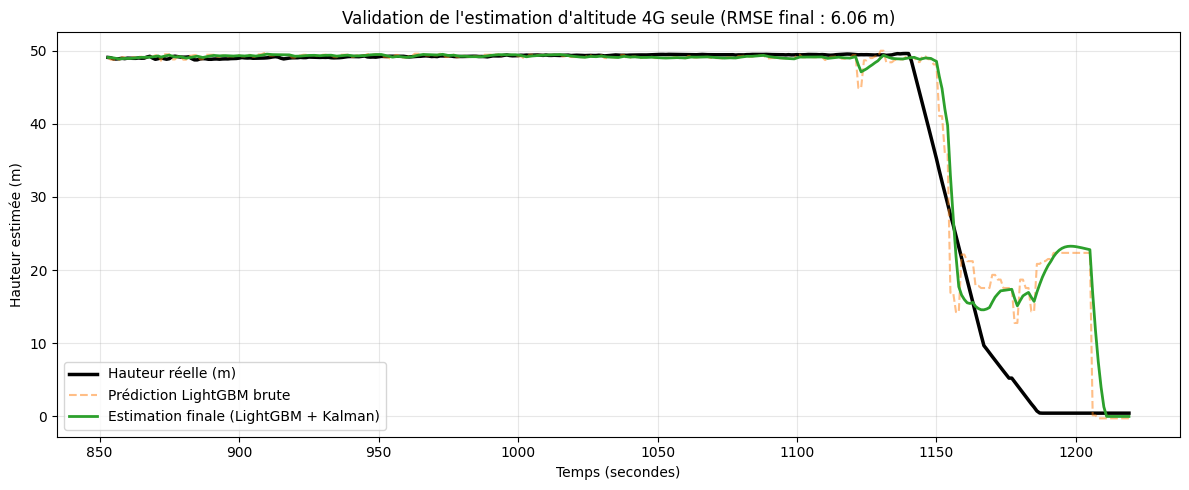


Modèle sauvegardé sous : passive_height_lgbm.txt (< 300 Ko)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# ==============================================================================
# ÉTAPE 1 : IMPORTATIONS ET CHARGEMENT DU FICHIER lte.csv
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

# Vérifie si lte.csv est déjà dans Colab, sinon ouvre la fenêtre d'importation
if not os.path.exists("lte.csv"):
    from google.colab import files
    print("Sélectionne ton fichier lte.csv depuis ton ordinateur :")
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]
else:
    filename = "lte.csv"

# sep=None détecte automatiquement si le fichier utilise des tabulations (\t) ou des virgules (,)
df_raw = pd.read_csv(filename, sep=None, engine="python")
print(f"\nFichier chargé : {filename} | Dimensions : {df_raw.shape[0]} lignes x {df_raw.shape[1]} colonnes")


# ==============================================================================
# ÉTAPE 2 : EXPLORATION DES DONNÉES (EDA)
# ==============================================================================
print("\n--- APERÇU DES COLONNES ET VALEURS MANQUANTES ---")
cols_utiles = ["technology", "rsrp", "rsrq", "rssi", "pci", "ta", "is_connected", "rel_time", "altitude"]
cols_presentes = [c for c in cols_utiles if c in df_raw.columns]
print(df_raw[cols_presentes].head(5))

print("\nValeurs non numériques ou manquantes détectées :")
for col in ["rsrp", "rsrq", "rssi", "ta", "altitude"]:
    if col in df_raw.columns:
        non_num = pd.to_numeric(df_raw[col], errors="coerce").isna().sum()
        print(f" - {col:10s} : {non_num} valeurs invalides / 'Unavailable'")


# ==============================================================================
# ÉTAPE 3 : NETTOYAGE ET PRÉPARATION (FEATURE ENGINEERING)
# ==============================================================================
df = df_raw.copy()

# 1. Conversion propre en nombres (remplace 'Unavailable' par NaN puis par une valeur par défaut)
for col in ["rsrp", "rsrq", "rssi", "ta", "altitude", "rel_time", "pci"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Suppression des lignes sans RSRP ou sans altitude de référence
df = df.dropna(subset=["rsrp", "altitude", "rel_time"]).copy()

# Remplacement des valeurs manquantes secondaires
df["ta_clean"] = df["ta"].fillna(-1.0)
df["rsrq_clean"] = df["rsrq"].fillna(-12.0)
df["rssi_clean"] = df["rssi"].fillna(df["rsrp"] + 15.0)
df["pci_clean"] = df["pci"].fillna(-1).astype(int)
df["is_connected"] = df["is_connected"].fillna(1).astype(int) if "is_connected" in df.columns else 1

# 2. Regroupement par seconde (1 Hz) et calcul de l'altitude relative par rapport au sol (0 m)
df["sec"] = (df["rel_time"] - df["rel_time"].min()).round().astype(int)
z_sol = df.loc[df["sec"] <= 5, "altitude"].median()
df["z_rel"] = (df["altitude"] - z_sol).clip(lower=0.0)

print(f"\n--- RÉSUMÉ APRÈS NETTOYAGE ---")
print(f"Durée totale        : {df['sec'].max()} secondes")
print(f"Altitude min / max  : {df['z_rel'].min():.2f} m -> {df['z_rel'].max():.2f} m")
print(f"RSRP min / max      : {df['rsrp'].min():.1f} dBm -> {df['rsrp'].max():.1f} dBm")
print(f"Antennes (PCI) vues : {df['pci_clean'].nunique()} cellule(s) unique(s)")

if df["z_rel"].max() < 5.0:
    print("ATTENTION : L'altitude maximale est inférieure à 5 m. Vérifie que ce fichier contient bien une montée !")

# Graphique d'exploration : Altitude réelle et RSRP au cours du temps
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(df["sec"], df["z_rel"], color="tab:blue", linewidth=2, label="Altitude réelle (m)")
ax1.set_xlabel("Temps (secondes)")
ax1.set_ylabel("Altitude relative (m)", color="tab:blue")
ax2 = ax1.twinx()
ax2.scatter(df["sec"], df["rsrp"], color="tab:orange", alpha=0.4, s=12, label="RSRP (dBm)")
ax2.set_ylabel("RSRP (dBm)", color="tab:orange")
plt.title("Exploration du vol : Évolution de l'altitude et du signal RSRP")
fig.tight_layout()
plt.show()

# 3. Extraction des variables invariantes au site (Delta-RSRP par rapport au sol)
TOP_K = 6
ground_df = df[df["sec"] <= 5]
ground_rsrp_map = ground_df.groupby("pci_clean")["rsrp"].mean().to_dict()

X_list, y_list, sec_list = [], [], []

for sec, group in df.groupby("sec"):
    rsrps = group["rsrp"].values.astype(float)
    pcis = group["pci_clean"].values

    # Écart de puissance par rapport au point de départ au sol (t <= 5s)
    deltas = [r - ground_rsrp_map.get(p, -135.0) for p, r in zip(pcis, rsrps)]

    deltas_pad = (sorted(deltas, reverse=True)[:TOP_K] + [0.0] * TOP_K)[:TOP_K]
    rsrps_pad = (sorted(rsrps, reverse=True)[:TOP_K] + [-140.0] * TOP_K)[:TOP_K]

    serving = group[group["is_connected"] == 1]
    serv_row = serving.iloc[0] if not serving.empty else group.iloc[0]

    features = deltas_pad + rsrps_pad + [
        float(serv_row["rsrp"]),
        float(serv_row["rsrq_clean"]),
        float(serv_row["rssi_clean"]),
        float(serv_row["ta_clean"]),
        float(len(group)),                                # Nombre de cellules visibles à l'instant t
        float(np.std(rsrps)) if len(rsrps) > 1 else 0.0,  # Dispersion des signaux
    ]
    X_list.append(features)
    y_list.append(float(group["z_rel"].mean()))
    sec_list.append(sec)

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.float32)
secs = np.array(sec_list)


# ==============================================================================
# ÉTAPE 4 : ENTRAÎNEMENT LIGHTGBM & VALIDATION (70% TRAIN / 30% TEST)
# ==============================================================================
split_idx = int(len(y) * 0.70)
X_train, y_train = X[:split_idx], y[:split_idx]
X_test, y_test = X[split_idx:], y[split_idx:]
secs_test = secs[split_idx:]

lgb_params = {
    "objective": "regression",
    "metric": "rmse",
    "boosting_type": "gbdt",
    "num_leaves": 31,
    "learning_rate": 0.05,
    "n_estimators": 250,
    "subsample_for_bin": 500,
    "min_child_samples": 10,
    "random_state": 42,
    "verbose": -1,
}

model = lgb.LGBMRegressor(**lgb_params)
model.fit(X_train, y_train)
raw_preds = model.predict(X_test)


# ==============================================================================
# ÉTAPE 5 : FILTRE DE KALMAN 1D & ÉVALUATION DES PERFORMANCES
# ==============================================================================
def apply_kalman_filter(z_measurements: np.ndarray, initial_z: float, ml_rmse: float = 2.0) -> np.ndarray:
    x_state = np.array([[initial_z], [0.0]])      # [hauteur z, vitesse verticale vz]
    P = np.array([[0.5, 0.0], [0.0, 0.5]])
    H = np.array([[1.0, 0.0]])
    R = np.array([[ml_rmse ** 2]])
    Q = np.array([[0.05, 0.0], [0.0, 0.08]])
    A = np.array([[1.0, 1.0], [0.0, 1.0]])

    filtered = []
    for z_meas in z_measurements:
        # Prédiction cinématique
        x_pred = A @ x_state
        P_pred = A @ P @ A.T + Q

        # Mise à jour avec la prédiction LightGBM
        y_res = np.array([[z_meas]]) - (H @ x_pred)
        S = H @ P_pred @ H.T + R
        K = P_pred @ H.T @ np.linalg.inv(S)

        x_state = x_pred + K @ y_res
        P = (np.eye(2) - K @ H) @ P_pred
        filtered.append(max(0.0, float(x_state[0, 0])))

    return np.array(filtered)

rmse_raw = root_mean_squared_error(y_test, raw_preds)
filtered_preds = apply_kalman_filter(raw_preds, initial_z=float(y_test[0]), ml_rmse=max(1.5, rmse_raw))
rmse_kalman = root_mean_squared_error(y_test, filtered_preds)
mae_kalman = mean_absolute_error(y_test, filtered_preds)

print(f"\n--- RÉSULTATS SUR LE JEU DE TEST ({len(y_test)} secondes) ---")
print(f"RMSE LightGBM brut         : {rmse_raw:.2f} m")
print(f"RMSE après Filtre Kalman   : {rmse_kalman:.2f} m")
print(f"Erreur moyenne (MAE)       : {mae_kalman:.2f} m")

# Visualisation comparative : Réel vs LightGBM brut vs LightGBM + Kalman
plt.figure(figsize=(12, 5))
plt.plot(secs_test, y_test, label="Hauteur réelle (m)", color="black", linewidth=2.5)
plt.plot(secs_test, raw_preds, label="Prédiction LightGBM brute", color="tab:orange", alpha=0.5, linestyle="--")
plt.plot(secs_test, filtered_preds, label="Estimation finale (LightGBM + Kalman)", color="tab:green", linewidth=2)
plt.xlabel("Temps (secondes)")
plt.ylabel("Hauteur estimée (m)")
plt.title(f"Validation de l'estimation d'altitude 4G seule (RMSE final : {rmse_kalman:.2f} m)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ==============================================================================
# ÉTAPE 6 : ENTRAÎNEMENT FINAL (100% DES DONNÉES) & EXPORT DU MODÈLE
# ==============================================================================
final_model = lgb.LGBMRegressor(**lgb_params)
final_model.fit(X, y)
final_model.booster_.save_model("passive_height_lgbm.txt")
print("\nModèle sauvegardé sous : passive_height_lgbm.txt (< 300 Ko)")

# Téléchargement automatique sur ton PC depuis Google Colab
try:
    from google.colab import files
    files.download("passive_height_lgbm.txt")
except ImportError:
    pass

In [2]:
# 1. Afficher les 5 secondes où l'erreur est la plus forte
erreurs = np.abs(y_test - raw_preds)
pires_indices = np.argsort(erreurs)[::-1][:5]

print("--- TOP 5 DES PLUS GROSSES ERREURS ---")
for idx in pires_indices:
    print(f"Seconde {secs_test[idx]:4d}s | Réel: {y_test[idx]:5.1f}m | Prédit: {raw_preds[idx]:5.1f}m | Écart: {erreurs[idx]:5.1f}m")

# 2. Tester un Filtre de Kalman plus réactif (R plus faible, Q adapté au mouvement)
def kalman_optimise(z_meas_arr, z0, R_val=4.0, q_vel=0.25):
    x = np.array([[z0], [0.0]])
    P = np.array([[1.0, 0.0], [0.0, 1.0]])
    H = np.array([[1.0, 0.0]])
    R = np.array([[R_val]])
    Q = np.array([[0.05, 0.0], [0.0, q_vel]])
    A = np.array([[1.0, 1.0], [0.0, 1.0]])

    out = []
    for z in z_meas_arr:
        x_p = A @ x
        P_p = A @ P @ A.T + Q
        K = P_p @ H.T @ np.linalg.inv(H @ P_p @ H.T + R)
        x = x_p + K @ (np.array([[z]]) - H @ x_p)
        P = (np.eye(2) - K @ H) @ P_p
        out.append(max(0.0, float(x[0, 0])))
    return np.array(out)

preds_opt = kalman_optimise(raw_preds, y_test[0], R_val=4.0, q_vel=0.25)
print(f"\nNouveau RMSE après réglage Kalman : {root_mean_squared_error(y_test, preds_opt):.2f} m")
print(f"Nouveau MAE après réglage Kalman  : {mean_absolute_error(y_test, preds_opt):.2f} m")

--- TOP 5 DES PLUS GROSSES ERREURS ---
Seconde 1196s | Réel:   0.5m | Prédit:  22.4m | Écart:  21.9m
Seconde 1197s | Réel:   0.5m | Prédit:  22.4m | Écart:  21.9m
Seconde 1198s | Réel:   0.5m | Prédit:  22.4m | Écart:  21.9m
Seconde 1199s | Réel:   0.5m | Prédit:  22.4m | Écart:  21.9m
Seconde 1192s | Réel:   0.5m | Prédit:  22.4m | Écart:  21.9m

Nouveau RMSE après réglage Kalman : 6.11 m
Nouveau MAE après réglage Kalman  : 2.56 m


In [3]:
# 1. Vérifier pourquoi t=1195s diffère de t=0s (changement de PCI, de RSRP ou de position GPS)
print("--- COMPARAISON DÉCOLLAGE (t=2s) vs ATTERRISSAGE (t=1196s) ---")
cols_check = [c for c in ["sec", "pci_clean", "rsrp", "rsrq_clean", "ta_clean", "latitude", "longitude", "z_rel"] if c in df.columns]
print(df[df["sec"].isin([2, 1196])][cols_check])

# 2. Ajouter des features temporelles (évolution du RSRP sur 3s et 5s) pour détecter montée vs descente
df_sec = df.groupby("sec").agg(
    rsrp_max=("rsrp", "max"),
    rsrp_mean=("rsrp", "mean"),
    rsrq_mean=("rsrq_clean", "mean"),
    ta_min=("ta_clean", "min"),
    n_cells=("pci_clean", "count"),
    z_rel=("z_rel", "mean")
).reset_index()

# Différentiels par rapport au sol + dérivées temporelles (vitesse de changement du signal)
rsrp_sol = df_sec.loc[df_sec["sec"] <= 5, "rsrp_max"].median()
df_sec["delta_sol"] = df_sec["rsrp_max"] - rsrp_sol
df_sec["diff_3s"] = df_sec["rsrp_max"].diff(3).fillna(0.0)
df_sec["diff_10s"] = df_sec["rsrp_max"].diff(10).fillna(0.0)
df_sec["std_5s"] = df_sec["rsrp_max"].rolling(5, min_periods=1).std().fillna(0.0)

feature_cols = ["delta_sol", "rsrp_max", "rsrp_mean", "rsrq_mean", "ta_min", "n_cells", "diff_3s", "diff_10s", "std_5s"]

# 3. Validation croisée en mélangeant des segments de 30s (évite de tester uniquement sur l'atterrissage décalé)
from sklearn.model_selection import GroupKFold
df_sec["segment"] = df_sec["sec"] // 30  # Blocs continus de 30 secondes

gkf = GroupKFold(n_splits=5)
oof_preds = np.zeros(len(df_sec))

for tr_idx, va_idx in gkf.split(df_sec, df_sec["z_rel"], df_sec["segment"]):
    m = lgb.LGBMRegressor(n_estimators=200, num_leaves=31, learning_rate=0.05, random_state=42, verbose=-1)
    m.fit(df_sec.iloc[tr_idx][feature_cols], df_sec.iloc[tr_idx]["z_rel"])
    oof_preds[va_idx] = m.predict(df_sec.iloc[va_idx][feature_cols])

print(f"\nRMSE global (validation croisée par segments de 30s) : {root_mean_squared_error(df_sec['z_rel'], oof_preds):.2f} m")
print(f"MAE global  (validation croisée par segments de 30s) : {mean_absolute_error(df_sec['z_rel'], oof_preds):.2f} m")

--- COMPARAISON DÉCOLLAGE (t=2s) vs ATTERRISSAGE (t=1196s) ---
       sec  pci_clean  rsrp  rsrq_clean  ta_clean   latitude  longitude  z_rel
2        2          2   -65          -6       0.0  35.727400 -78.696316  0.004
1987  1196          2   -62          -6      -1.0  35.727398 -78.696320  0.451
1988  1196          1   -75         -17      -1.0  35.727398 -78.696320  0.451

RMSE global (validation croisée par segments de 30s) : 3.16 m
MAE global  (validation croisée par segments de 30s) : 1.06 m


In [4]:
# Features nettoyées (sans le TA instable en 4G)
feature_cols_v2 = ["delta_sol", "rsrp_max", "rsrp_mean", "rsrq_mean", "n_cells", "diff_3s", "diff_10s", "std_5s"]

final_model_v2 = lgb.LGBMRegressor(
    n_estimators=200,
    num_leaves=31,
    learning_rate=0.05,
    random_state=42,
    verbose=-1
)
final_model_v2.fit(df_sec[feature_cols_v2], df_sec["z_rel"])
final_model_v2.booster_.save_model("passive_height_lgbm_v2.txt")

from google.colab import files
files.download("passive_height_lgbm_v2.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>